# Bike demand forecasting
### A reproducible model notebook for a future MLOps project

Predict **total bike rentals in the next hour** using calendar information and
previously observed rental counts. Compare a weekly seasonal baseline with a
histogram gradient-boosting model, select a configuration on validation data,
and report an untouched chronological test period.

The target is demand across the **whole Capital Bikeshare system**, not the
availability of bicycles at an individual station.

**Start here:** run the notebook from top to bottom with Python 3.12. The complete
ZIP contains the source CSV and pinned requirements. The notebook alone can
download the same CSV from UCI and verify its checksum. Run it in a directory
where it can create `data/` and `artifacts/`.

**Data:** [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset),
Hadi Fanaee-T (2013), DOI [10.24432/C5W894](https://doi.org/10.24432/C5W894),
CC BY 4.0. `hour.csv` is redistributed unchanged in the complete package.

## Results at a glance

**Held-out period: October-December 2012.** These are rolling one-hour-ahead
forecasts with a fixed fitted model and observed history available before each
forecast. The selected configuration was chosen on July-September validation
MAE and refitted using only earlier target hours.

| Test metric | Weekly seasonal baseline | Gradient boosting |
|---|---:|---:|
| MAE, rentals/hour | 70.67 | 26.84 |
| RMSE, rentals/hour | 117.78 | 43.80 |
| WAPE | 32.10% | 12.19% |

**MAE reduction: 62.0%.** Evaluation covers
2,124 hours (97.97% of
recorded target hours in this period). Both methods use the same evaluation
hours. Results depend on the forecast timing and coverage rules described below.

The delivered notebook was executed from top to bottom. All feature-causality,
history-only inference, chronological-split, and model-reload checks passed.


## 1. Define exactly what is being predicted

For target hour $h$, issue the forecast immediately after the count for hour
$h-1$ becomes available. This assumes zero ingestion delay and must be revisited
when the future service is designed.

| Item | Decision |
|---|---|
| Target | Total rentals during hour $h$ (`cnt`) |
| Horizon | One hour ahead |
| Calendar | Hour, weekday, month, year, and day of year for $h$ |
| Demand history | Counts from $h-1$, $h-2$, $h-3$, $h-24$, $h-48$, and $h-168$; trailing statistics |
| Baseline | Same hour in the previous week: $hat y_h=y_{h-168}$ |
| Primary metric | Mean absolute error (MAE), in rentals per forecast hour |
| Evaluation | Rolling one-step forecasts with a fixed fitted model |

During validation and testing, observed counts from earlier hours become
available before the next forecast. This is appropriate for a service that
predicts one hour at a time; it does not measure a single forecast issued months
in advance.

`casual` and `registered` add up to the current target, so they are excluded.
Weather recorded during the target hour is also excluded. This first version
requires no future weather forecasts. Missing hourly records remain unknown;
they are not replaced with zero demand or interpolated from future values.

## 2. Environment and configuration

Use `python -m pip install -r requirements.txt` from the complete package, then
select that Python environment in Jupyter or VS Code. For the standalone
notebook, install `numpy pandas scikit-learn matplotlib joblib threadpoolctl
ipykernel` in your notebook environment.

The dates below are fixed before fitting. The small candidate search uses only
the validation period. The test period is reserved for the final evaluation.

In [1]:
%matplotlib inline

from pathlib import Path
from io import BytesIO
from urllib.request import Request, urlopen
from zipfile import ZipFile
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from threadpoolctl import threadpool_limits

SEED = 42
VALIDATION_START = pd.Timestamp('2012-07-01 00:00:00')
TEST_START = pd.Timestamp('2012-10-01 00:00:00')
DATA_DIR = Path('data')
ARTIFACT_DIR = Path('artifacts')
DATA_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({
    'figure.figsize': (11, 4),
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.alpha': 0.18,
    'font.size': 10,
    'savefig.bbox': 'tight',
})
COLORS = {'actual': '#172B4D', 'baseline': '#C67C30', 'model': '#008C95'}

versions = {
    name: importlib.metadata.version(name)
    for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'joblib', 'threadpoolctl']
}
print('Python:', platform.python_version())
display(pd.Series(versions, name='version').to_frame())

No event loop hook running.
Python: 3.12.14


,version
numpy,2.3.5
pandas,2.2.3
scikit-learn,1.8.0
matplotlib,3.10.8
joblib,1.5.3
threadpoolctl,3.6.0


## 3. Load the official hourly data

An existing `data/hour.csv` is used first. Otherwise, download the official UCI
archive and read only its `hour.csv` member. The SHA-256 check identifies the
exact data bytes used for this experiment.

In [2]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'
EXPECTED_CSV_SHA256 = 'e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f'
CSV_PATH = DATA_DIR / 'hour.csv'

if not CSV_PATH.exists():
    request = Request(DATA_URL, headers={'User-Agent': 'bike-demand-notebook/1.0'})
    try:
        with urlopen(request, timeout=30) as response:
            archive_bytes = response.read()
        with ZipFile(BytesIO(archive_bytes)) as archive:
            member = next(name for name in archive.namelist() if Path(name).name == 'hour.csv')
            csv_bytes = archive.read(member)
    except Exception as exc:
        raise RuntimeError(
            'Could not download the UCI data. Extract the complete starter ZIP '
            'or place the official hour.csv in the data/ directory, then rerun.'
        ) from exc
    if hashlib.sha256(csv_bytes).hexdigest() != EXPECTED_CSV_SHA256:
        raise ValueError('The downloaded CSV does not match the expected dataset version.')
    CSV_PATH.write_bytes(csv_bytes)

data_sha256 = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
if data_sha256 != EXPECTED_CSV_SHA256:
    raise ValueError('data/hour.csv has a different checksum; use the original UCI CSV.')

raw = pd.read_csv(CSV_PATH)
required_columns = {'dteday', 'hr', 'cnt', 'casual', 'registered'}
assert required_columns.issubset(raw.columns)
assert raw[list(required_columns)].notna().all().all()
assert raw['hr'].between(0, 23).all()
assert raw['cnt'].ge(0).all()
assert np.array_equal(raw['cnt'].to_numpy(), (raw['casual'] + raw['registered']).to_numpy())

timestamp = pd.to_datetime(raw['dteday']) + pd.to_timedelta(raw['hr'], unit='h')
assert timestamp.is_unique, 'Duplicate local timestamp: investigate before modelling.'
observed = raw.assign(timestamp=timestamp).set_index('timestamp').sort_index()

# Reindex BEFORE shifting: one row must represent one clock hour.
full_index = pd.date_range(observed.index.min(), observed.index.max(), freq='h', name='timestamp')
hourly = observed.reindex(full_index)
missing_hours = int(hourly['cnt'].isna().sum())

audit = pd.Series({
    'recorded rows': len(observed),
    'hours on complete calendar grid': len(hourly),
    'unrecorded hours': missing_hours,
    'first timestamp': str(hourly.index.min()),
    'last timestamp': str(hourly.index.max()),
    'minimum recorded count': int(observed['cnt'].min()),
    'maximum recorded count': int(observed['cnt'].max()),
}, name='value')
display(audit.to_frame())
print('CSV SHA-256:', data_sha256)
display(raw.head())

CSV SHA-256: e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f


,value
recorded rows,17379
hours on complete calendar grid,17544
unrecorded hours,165
first timestamp,2011-01-01 00:00:00
last timestamp,2012-12-31 23:00:00
minimum recorded count,1
maximum recorded count,977


,instant,dteday,season,yr,mnth,hr,...,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,...,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,...,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,...,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,...,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,...,0.2879,0.75,0.0,0,1,1


The original CSV has **17,379 rows** and **165 unrecorded hours** between its
first and last timestamps. These are absent records, even though the supplied
rows themselves have no missing values. A plain row-based shift on the original
CSV would sometimes represent the wrong elapsed time.

We retain the source's local, timezone-naive clock labels. A deployed service
will need an explicit timezone and daylight-saving-time policy.

## 4. Explore the training period

Only observations before the validation start are used for these exploratory
plots. The first plot shows the mean of available hourly counts on each day;
it is not a daily total with missing hours filled in.

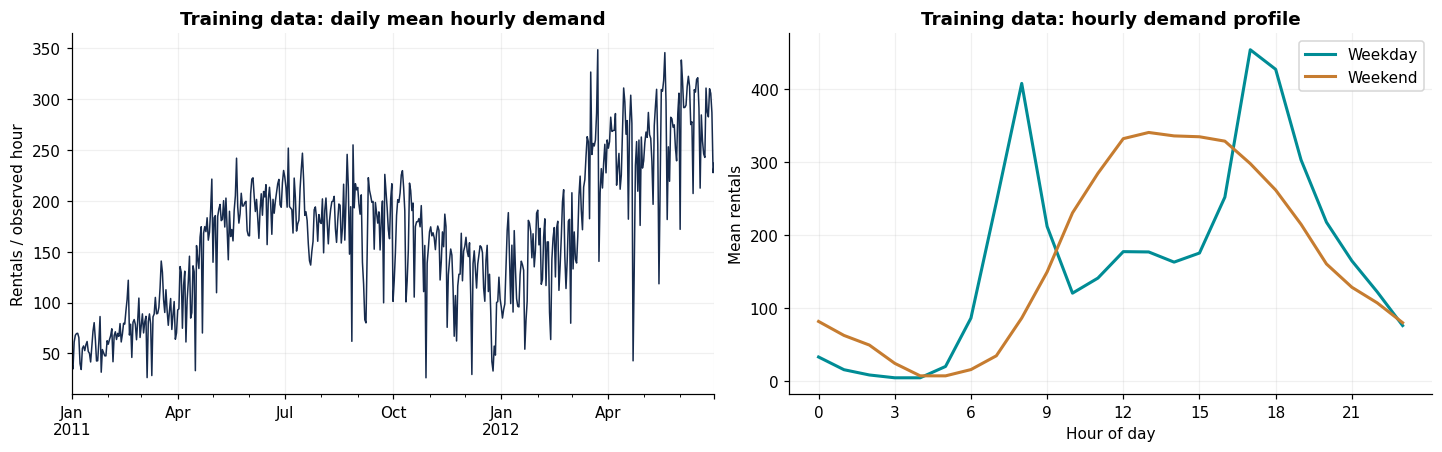

In [3]:
eda = hourly.loc[hourly.index < VALIDATION_START, ['cnt']].copy()
eda['hour'] = eda.index.hour
eda['is_weekend'] = eda.index.dayofweek >= 5

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
eda['cnt'].resample('D').mean().plot(ax=axes[0], color=COLORS['actual'], linewidth=1)
axes[0].set(title='Training data: daily mean hourly demand', xlabel='', ylabel='Rentals / observed hour')
profiles = eda.groupby(['hour', 'is_weekend'])['cnt'].mean().unstack()
profiles.columns = ['Weekday', 'Weekend']
profiles.plot(ax=axes[1], color=[COLORS['model'], COLORS['baseline']], linewidth=2)
axes[1].set(title='Training data: hourly demand profile', xlabel='Hour of day', ylabel='Mean rentals')
axes[1].set_xticks(range(0, 24, 3))
fig.savefig(ARTIFACT_DIR / 'training_patterns.png')
plt.show()

## 5. Build features using only available history

Every row is indexed by its **target hour**. For example, the feature `lag_1h`
at 10:00 is the observed count for 09:00. All trailing statistics operate on
`cnt.shift(1)` before taking a rolling window.

| Feature group | Inputs |
|---|---|
| Calendar | Hour, day of week, weekend indicator, month, year, day of year |
| Demand lags | 1, 2, 3, 24, 48, 168 hours before the target hour |
| Trailing demand | Mean over 3, 24, 168 past hours; standard deviation over 24 past hours |
| Data availability | Number of recorded counts in the previous 24 clock hours |

Rolling means require complete windows and stay missing otherwise. Histogram
gradient boosting can handle those missing feature values. No learned
imputation or scaling is fitted on the full dataset.

In [4]:
def make_features(history: pd.DataFrame) -> pd.DataFrame:
    """Create target-hour features from an hourly grid containing a cnt column.

    The row at hour h never uses cnt at h or later. Missing cnt values remain NaN.
    """
    if not isinstance(history.index, pd.DatetimeIndex) or not history.index.is_monotonic_increasing:
        raise ValueError('history must have a sorted DatetimeIndex.')
    if not history.index.is_unique:
        raise ValueError('history must have unique timestamps.')
    expected = pd.date_range(history.index.min(), history.index.max(), freq='h')
    if not history.index.equals(expected.rename(history.index.name)):
        raise ValueError('Reindex the history to a complete hourly grid first.')

    idx = history.index
    X = pd.DataFrame(index=idx)
    X['hour'] = idx.hour
    X['day_of_week'] = idx.dayofweek
    X['is_weekend'] = (idx.dayofweek >= 5).astype(int)
    X['month'] = idx.month
    X['year'] = idx.year
    X['day_of_year'] = idx.dayofyear

    demand = history['cnt'].astype(float)
    for lag in [1, 2, 3, 24, 48, 168]:
        X[f'lag_{lag}h'] = demand.shift(lag)

    past = demand.shift(1)
    for window in [3, 24, 168]:
        X[f'rolling_mean_{window}h'] = past.rolling(window, min_periods=window).mean()
    X['rolling_std_24h'] = past.rolling(24, min_periods=24).std()
    X['observations_last_24h'] = past.rolling(24, min_periods=1).count()
    return X


X_all = make_features(hourly[['cnt']])
y_all = hourly['cnt'].rename('actual')
baseline_all = hourly['cnt'].shift(168).rename('weekly_baseline')
feature_columns = X_all.columns.tolist()

# Common cohort: target, most recent observed count, and weekly baseline must exist.
# Other missing lag / rolling features are supported by the model.
eligible = y_all.notna() & X_all['lag_1h'].notna() & baseline_all.notna()
assert not {'cnt', 'casual', 'registered', 'temp', 'atemp', 'hum', 'windspeed'}.intersection(feature_columns)
assert X_all.index.equals(y_all.index)
display(X_all.loc[eligible].head().T)
print(f'{len(feature_columns)} features; {int(eligible.sum()):,} eligible forecast hours.')

17 features; 17,010 eligible forecast hours.


timestamp,2011-01-08 00:00:00,2011-01-08 01:00:00,2011-01-08 02:00:00,2011-01-08 03:00:00,2011-01-08 04:00:00
hour,0.0,1.000000,2.000000,3.0,4.000000
day_of_week,5.0,5.000000,5.000000,5.0,5.000000
is_weekend,1.0,1.000000,1.000000,1.0,1.000000
month,1.0,1.000000,1.000000,1.0,1.000000
year,2011.0,2011.000000,2011.000000,2011.0,2011.000000
day_of_year,8.0,8.000000,8.000000,8.0,8.000000
lag_1h,15.0,25.000000,16.000000,16.0,7.000000
lag_2h,36.0,15.000000,25.000000,16.0,16.000000
lag_3h,39.0,36.000000,15.000000,25.0,16.000000
lag_24h,17.0,7.000000,1.000000,NaN,1.000000


### Verify that future values cannot change past features

This check changes the target count at a chosen hour and every later hour.
Features up to and including that hour must remain identical. Features for the
following hour should respond, because its most recent count has changed.

In [5]:
cutoff = pd.Timestamp('2012-08-15 12:00:00')
perturbed = hourly[['cnt']].copy()
perturbed.loc[cutoff:, 'cnt'] = 99999.0
X_perturbed = make_features(perturbed)
pd.testing.assert_frame_equal(X_all.loc[:cutoff], X_perturbed.loc[:cutoff])
assert X_perturbed.loc[cutoff + pd.Timedelta(hours=1), 'lag_1h'] == 99999.0
assert X_perturbed.loc[cutoff + pd.Timedelta(hours=1), 'lag_1h'] != X_all.loc[cutoff + pd.Timedelta(hours=1), 'lag_1h']

for lag in [1, 24, 168]:
    sample_hour = pd.Timestamp('2012-08-15 12:00:00')
    assert X_all.loc[sample_hour, f'lag_{lag}h'] == hourly.loc[sample_hour - pd.Timedelta(hours=lag), 'cnt']

print('Passed: causal feature check, future perturbation sensitivity, and clock-hour lag checks.')

Passed: causal feature check, future perturbation sensitivity, and clock-hour lag checks.


## 6. Split chronologically and report coverage

| Split | Target-hour dates | Purpose |
|---|---|---|
| Training | Before 2012-07-01 | Fit each candidate |
| Validation | 2012-07-01 through 2012-09-30 | Choose one configuration by MAE |
| Test | 2012-10-01 through 2012-12-31 | Evaluate the final model once |

All models are compared on the same eligible hours. The table exposes how many
recorded target hours are excluded because recent demand or the weekly baseline
is unavailable. These metrics describe that covered cohort. A production
fallback for the remaining hours is future work.

At the start of a split, lag features may reference earlier splits: that is
historical information available at the forecast origin. No training labels
come from a later split.

In [6]:
period_masks = {
    'train': hourly.index < VALIDATION_START,
    'validation': (hourly.index >= VALIDATION_START) & (hourly.index < TEST_START),
    'test': hourly.index >= TEST_START,
}
splits = {name: pd.Series(mask, index=hourly.index) & eligible for name, mask in period_masks.items()}
coverage_rows = []
for name, period_mask in period_masks.items():
    recorded = int((pd.Series(period_mask, index=hourly.index) & y_all.notna()).sum())
    retained = int(splits[name].sum())
    index = hourly.index[splits[name]]
    coverage_rows.append({
        'split': name,
        'first eligible target': str(index.min()),
        'last eligible target': str(index.max()),
        'recorded target hours': recorded,
        'evaluated hours': retained,
        'coverage (%)': round(100 * retained / recorded, 2),
    })
coverage = pd.DataFrame(coverage_rows).set_index('split')
display(coverage)

X_train, y_train = X_all.loc[splits['train']], y_all.loc[splits['train']]
X_val, y_val = X_all.loc[splits['validation']], y_all.loc[splits['validation']]
assert X_train.index.max() < X_val.index.min()
assert X_val.index.max() < X_all.loc[splits['test']].index.min()
assert not (splits['train'] & splits['validation']).any()
assert not (splits['validation'] & splits['test']).any()

,first eligible target,last eligible target,recorded target hours,evaluated hours,coverage (%)
split,,,,,
train,2011-01-08 00:00:00,2012-06-30 23:00:00,13003,12678,97.50
validation,2012-07-01 00:00:00,2012-09-30 23:00:00,2208,2208,100.00
test,2012-10-01 00:00:00,2012-12-31 23:00:00,2168,2124,97.97


## 7. Compare the weekly baseline and a small boosting search

MAE is the selection metric. RMSE makes large errors more visible. WAPE is the
sum of absolute errors divided by total observed demand, expressed as a
percentage; it is an aggregate metric, not a per-hour percentage accuracy.
Mean bias is positive when the model overpredicts on average.

Three predeclared configurations keep the search small. Poisson loss supports
nonnegative count predictions. Early stopping is disabled, so the estimator
does not create an internal random validation split. All candidates see the
same training and validation dates.

In [7]:
def score_forecasts(actual, predicted) -> dict:
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    assert actual.shape == predicted.shape
    assert np.isfinite(actual).all() and np.isfinite(predicted).all()
    denominator = np.abs(actual).sum()
    return {
        'MAE': float(mean_absolute_error(actual, predicted)),
        'RMSE': float(root_mean_squared_error(actual, predicted)),
        'WAPE (%)': float(100 * np.abs(actual - predicted).sum() / denominator) if denominator else np.nan,
        'mean bias': float(np.mean(predicted - actual)),
    }


common_params = dict(
    loss='poisson',
    learning_rate=0.06,
    max_iter=250,
    early_stopping=False,
    random_state=SEED,
)
candidates = {
    'HGB compact': dict(max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=1.0),
    'HGB balanced': dict(max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1.0),
    'HGB regularized': dict(max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=5.0),
}

validation_rows = [{
    'model': 'Weekly seasonal baseline',
    **score_forecasts(y_val, baseline_all.loc[splits['validation']]),
    'fit seconds': 0.0,
}]
candidate_models = {}
for name, params in candidates.items():
    model = HistGradientBoostingRegressor(**common_params, **params)
    started = time.perf_counter()
    with threadpool_limits(limits=2):
        model.fit(X_train, y_train)
        fit_elapsed = time.perf_counter() - started
        prediction = model.predict(X_val)
    candidate_models[name] = model
    validation_rows.append({
        'model': name,
        **score_forecasts(y_val, prediction),
        'fit seconds': fit_elapsed,
    })

validation_results = pd.DataFrame(validation_rows).set_index('model').sort_values('MAE')
best_name = validation_results.loc[list(candidates), 'MAE'].idxmin()
best_params = {**common_params, **candidates[best_name]}
selected_validation_model = candidate_models[best_name]
display(validation_results.round(3))
print('Selected using validation MAE only:', best_name)
print('Selected configuration:', json.dumps(best_params, indent=2))

Selected using validation MAE only: HGB balanced
Selected configuration: {
  "loss": "poisson",
  "learning_rate": 0.06,
  "max_iter": 250,
  "early_stopping": false,
  "random_state": 42,
  "max_leaf_nodes": 31,
  "min_samples_leaf": 20,
  "l2_regularization": 1.0
}


,MAE,RMSE,WAPE (%),mean bias,fit seconds
model,,,,,
HGB balanced,33.480,52.913,11.611,-7.158,0.666
HGB regularized,34.139,54.606,11.839,-8.385,0.692
HGB compact,34.651,54.830,12.017,-7.286,0.489
Weekly seasonal baseline,55.998,97.892,19.420,-2.936,0.000


## 8. Inspect which features help on validation data

Permutation importance measures the increase in validation MAE when a feature
is shuffled. It is computed with the selected model fitted on training data
only. Correlated lag features can share predictive information, so these
values are descriptive and do not establish causality.

,increase in MAE,standard deviation
feature,,
lag_1h,144.109,1.327
hour,45.164,1.918
lag_168h,16.973,0.455
day_of_week,7.747,0.633
lag_3h,6.976,0.324
lag_24h,6.584,0.379
lag_2h,6.195,0.037
rolling_mean_3h,1.827,0.042


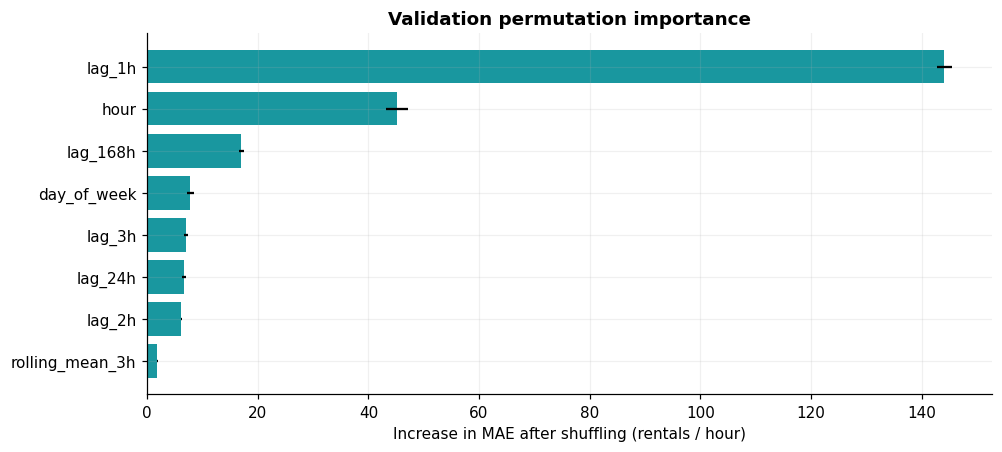

In [8]:
with threadpool_limits(limits=2):
    importance = permutation_importance(
        selected_validation_model,
        X_val,
        y_val,
        scoring='neg_mean_absolute_error',
        n_repeats=3,
        random_state=SEED,
        n_jobs=1,
    )
importance_table = pd.DataFrame({
    'feature': feature_columns,
    'increase in MAE': importance.importances_mean,
    'standard deviation': importance.importances_std,
}).set_index('feature').sort_values('increase in MAE', ascending=False)
display(importance_table.head(8).round(3))

top_importance = importance_table.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.barh(top_importance.index, top_importance['increase in MAE'],
        xerr=top_importance['standard deviation'], color=COLORS['model'], alpha=0.9)
ax.set(title='Validation permutation importance', xlabel='Increase in MAE after shuffling (rentals / hour)')
fig.savefig(ARTIFACT_DIR / 'validation_feature_importance.png')
plt.show()

## 9. Refit the chosen configuration and evaluate the test period

The configuration is now fixed. Refit it on training plus validation targets
strictly before 2012-10-01, then evaluate October–December once. Earlier actual
test counts are used as history as each forecast hour advances. Model weights
stay fixed throughout the test period.

The following plots and error tables describe this final result. They are not
used to choose or retune the model.

In [9]:
fit_mask = splits['train'] | splits['validation']
test_mask = splits['test']
X_fit, y_fit = X_all.loc[fit_mask], y_all.loc[fit_mask]
X_test, y_test = X_all.loc[test_mask], y_all.loc[test_mask]
final_model = HistGradientBoostingRegressor(**best_params)

started = time.perf_counter()
with threadpool_limits(limits=2):
    final_model.fit(X_fit, y_fit)
    final_fit_seconds = time.perf_counter() - started
    test_prediction = final_model.predict(X_test)
assert X_fit.index.max() < X_test.index.min()
assert np.isfinite(test_prediction).all() and (test_prediction >= 0).all()

test_predictions = pd.DataFrame({
    'actual': y_test,
    'weekly_baseline': baseline_all.loc[test_mask],
    'gradient_boosting': test_prediction,
})
test_results = pd.DataFrame({
    'Weekly seasonal baseline': score_forecasts(y_test, test_predictions['weekly_baseline']),
    'Gradient boosting': score_forecasts(y_test, test_predictions['gradient_boosting']),
}).T
mae_reduction_pct = 100 * (
    1 - test_results.loc['Gradient boosting', 'MAE'] / test_results.loc['Weekly seasonal baseline', 'MAE']
)

display(test_results.round(3))
print(f'Final fit: {len(X_fit):,} historical hours in {final_fit_seconds:.2f} seconds.')
print(f'Test: {len(X_test):,} covered hours; MAE reduction versus weekly baseline: {mae_reduction_pct:.1f}%.')

Final fit: 14,886 historical hours in 0.63 seconds.
Test: 2,124 covered hours; MAE reduction versus weekly baseline: 62.0%.


,MAE,RMSE,WAPE (%),mean bias
Weekly seasonal baseline,70.665,117.780,32.101,17.852
Gradient boosting,26.844,43.799,12.194,1.783


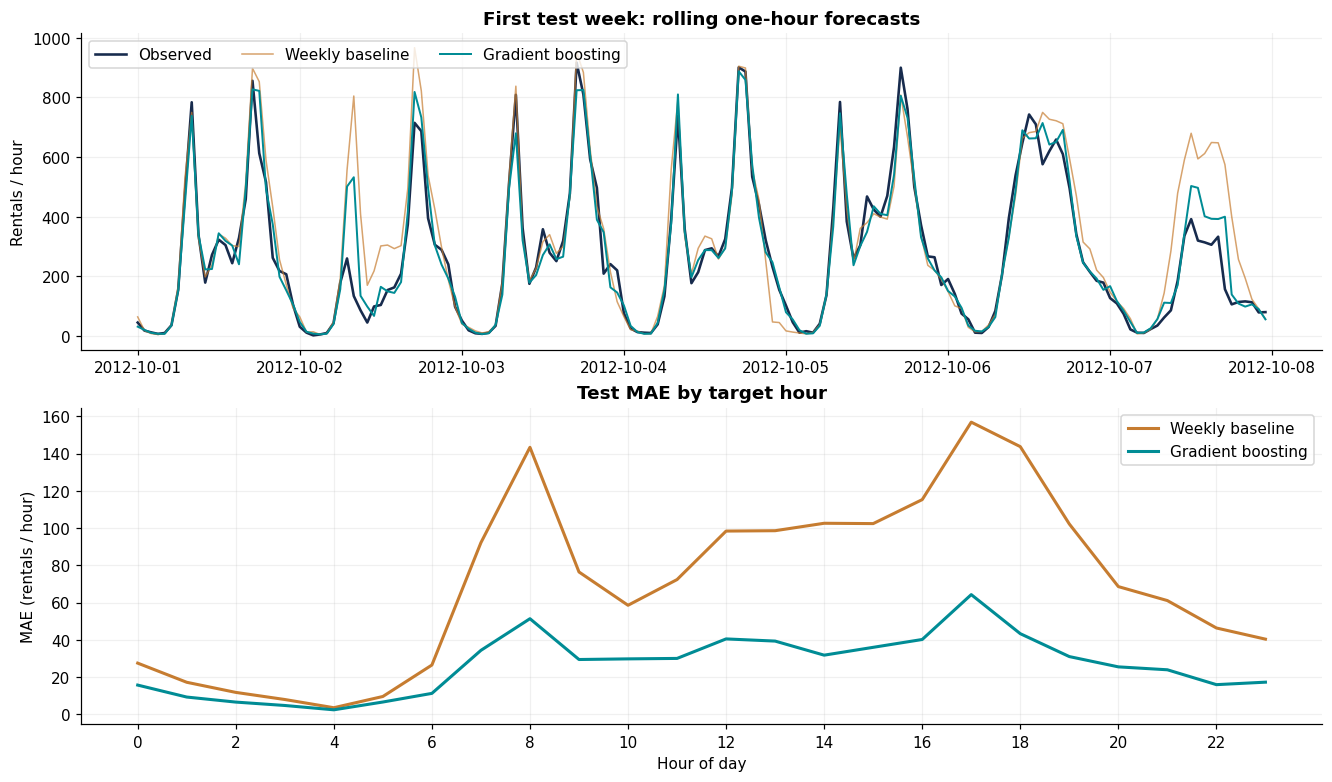

In [10]:
# Display the first test week, chosen in advance rather than selected for good predictions.
first_week_index = pd.date_range(TEST_START, TEST_START + pd.Timedelta(days=7), freq='h', inclusive='left')
first_week = test_predictions.reindex(first_week_index)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(first_week.index, first_week['actual'], color=COLORS['actual'], label='Observed', linewidth=1.7)
axes[0].plot(first_week.index, first_week['weekly_baseline'], color=COLORS['baseline'],
             label='Weekly baseline', linewidth=1, alpha=0.7)
axes[0].plot(first_week.index, first_week['gradient_boosting'], color=COLORS['model'],
             label='Gradient boosting', linewidth=1.3)
axes[0].set(title='First test week: rolling one-hour forecasts', xlabel='', ylabel='Rentals / hour')
axes[0].legend(ncol=3, loc='upper left')
residuals = pd.DataFrame({
    'Weekly baseline': (test_predictions['weekly_baseline'] - y_test).abs(),
    'Gradient boosting': (test_predictions['gradient_boosting'] - y_test).abs(),
})
residuals.groupby(residuals.index.hour).mean().plot(
    ax=axes[1], color=[COLORS['baseline'], COLORS['model']], linewidth=2,
)
axes[1].set(title='Test MAE by target hour', xlabel='Hour of day', ylabel='MAE (rentals / hour)')
axes[1].set_xticks(range(0, 24, 2))
fig.savefig(ARTIFACT_DIR / 'test_forecasts_and_hourly_errors.png')
plt.show()

### Check stability over time and inspect large errors

Monthly metrics expose variation within the holdout period. The largest errors
are diagnostic examples, not evidence of their causes: an unusual day can
reflect events or conditions absent from this model's inputs.

In [11]:
monthly_rows = []
for month, group in test_predictions.groupby(test_predictions.index.to_period('M')):
    for column, label in [('weekly_baseline', 'Weekly baseline'), ('gradient_boosting', 'Gradient boosting')]:
        monthly_rows.append({
            'month': str(month),
            'model': label,
            'hours': len(group),
            **score_forecasts(group['actual'], group[column]),
        })
monthly_results = pd.DataFrame(monthly_rows)
display(monthly_results.round(3))

largest_errors = test_predictions.assign(
    absolute_error=(test_predictions['gradient_boosting'] - test_predictions['actual']).abs()
).nlargest(8, 'absolute_error')
display(largest_errors.round(2))

,month,model,hours,MAE,RMSE,WAPE (%),mean bias
0,2012-10,Weekly baseline,707,66.925,116.301,23.810,13.001
1,2012-10,Gradient boosting,707,33.923,54.990,12.069,-0.277
2,2012-11,Weekly baseline,679,80.043,125.420,37.444,16.617
3,2012-11,Gradient boosting,679,26.637,41.330,12.461,3.423
4,2012-12,Weekly baseline,738,65.621,111.777,39.150,23.634
5,2012-12,Gradient boosting,738,20.252,32.444,12.083,2.247


,actual,weekly_baseline,gradient_boosting,absolute_error
timestamp,,,,
2012-10-02 08:00:00,134.0,805.0,532.44,398.44
2012-10-19 17:00:00,425.0,837.0,779.14,354.14
2012-10-15 08:00:00,737.0,397.0,482.48,254.52
2012-10-07 17:00:00,157.0,575.0,400.08,243.08
2012-10-02 07:00:00,260.0,556.0,501.31,241.31
2012-10-19 18:00:00,233.0,642.0,469.56,236.56
2012-10-11 19:00:00,743.0,534.0,516.96,226.04
2012-10-19 07:00:00,154.0,392.0,365.46,211.46


## 10. Construct one forecast from a history snapshot

This function receives historical counts through the forecast origin and
constructs the next row without access to the next actual count. It is a small
starting point for later extraction into a serving module. The complete hourly
history preserves clock-time lags; a service will need at least 168 prior hours
and an explicit policy for missing observations.

The example uses the first covered test hour and verifies that building features
from its history snapshot produces exactly the same row as offline evaluation.

In [12]:
def make_next_hour_row(history: pd.DataFrame, expected_features: list[str]) -> pd.DataFrame:
    """Build one feature row from counts available through the forecast origin."""
    if history.empty or not isinstance(history.index, pd.DatetimeIndex):
        raise ValueError('Supply nonempty historical counts with a DatetimeIndex.')
    if not history.index.is_unique or not history.index.is_monotonic_increasing:
        raise ValueError('History timestamps must be sorted and unique.')
    if pd.isna(history['cnt'].iloc[-1]):
        raise ValueError('The most recent hourly count has not arrived yet.')
    if any(history.index != history.index.floor('h')):
        raise ValueError('History timestamps must identify whole hours.')

    target_hour = history.index.max() + pd.Timedelta(hours=1)
    full_history = history[['cnt']].reindex(pd.date_range(
        history.index.min(), target_hour, freq='h', name=history.index.name,
    ))
    row = make_features(full_history).loc[[target_hour], expected_features]
    if pd.isna(row['lag_168h'].iloc[0]):
        raise ValueError('The weekly reference count is unavailable for this forecast.')
    return row


demo_target = X_test.index[0]
demo_history = hourly.loc[hourly.index < demo_target, ['cnt']]
next_row = make_next_hour_row(demo_history, feature_columns)
pd.testing.assert_frame_equal(next_row, X_test.loc[[demo_target]])
with threadpool_limits(limits=2):
    next_prediction = float(final_model.predict(next_row)[0])
np.testing.assert_allclose(next_prediction, test_predictions.loc[demo_target, 'gradient_boosting'])

display(pd.Series({
    'history available through': str(demo_history.index.max()),
    'target hour': str(demo_target),
    'forecast rentals': round(next_prediction, 2),
    'subsequently observed rentals': float(y_test.loc[demo_target]),
}, name='example').to_frame())
print('Passed: history-only feature construction matches the offline evaluation row.')

Passed: history-only feature construction matches the offline evaluation row.


,example
history available through,2012-09-30 23:00:00
target hour,2012-10-01 00:00:00
forecast rentals,31.22
subsequently observed rentals,45.0


## 11. Save the model and experiment evidence

The artifact stores the fitted estimator and its ordered feature schema.
Feature construction remains explicit Python code in this notebook. An API
will need the same feature function and demand history; the estimator alone
cannot accept an arbitrary timestamp and produce a forecast.

The manifest records the data checksum, split boundaries, fitted configuration,
evaluation coverage, and package versions. Model files use joblib and should be
loaded with the same scikit-learn version recorded here.

In [13]:
model_bundle = {
    'estimator': final_model,
    'feature_columns': feature_columns,
    'feature_builder_version': 'calendar-and-demand-history-v1',
    'forecast_horizon_hours': 1,
    'target': 'system-wide hourly rental count',
    'training_target_end': str(X_fit.index.max()),
    'data_sha256': data_sha256,
    'sklearn_version': sklearn.__version__,
}
model_path = ARTIFACT_DIR / 'bike_demand_model.joblib'
joblib.dump(model_bundle, model_path, compress=3)

manifest = {
    'dataset': {
        'name': 'UCI Bike Sharing - hour.csv',
        'url': DATA_URL,
        'doi': '10.24432/C5W894',
        'license': 'CC BY 4.0',
        'sha256': data_sha256,
        'recorded_rows': len(observed),
        'unrecorded_hours': missing_hours,
    },
    'forecast': {
        'horizon_hours': 1,
        'count_availability': 'Previous hourly count available immediately after that hour ends',
        'evaluation': 'Rolling one-step forecasts; fixed model during holdout',
        'timezone': 'Source local clock labels; timezone-naive',
    },
    'validation_start': str(VALIDATION_START),
    'test_start': str(TEST_START),
    'final_training_target_end': str(X_fit.index.max()),
    'selected_candidate': best_name,
    'selection_metric': 'Validation MAE',
    'parameters': best_params,
    'features': feature_columns,
    'coverage': coverage.reset_index().to_dict(orient='records'),
    'versions': {'python': platform.python_version(), **versions},
    'seed': SEED,
}
metrics = {
    'validation': validation_results.to_dict(orient='index'),
    'test': test_results.to_dict(orient='index'),
    'test_mae_reduction_pct': float(mae_reduction_pct),
    'test_evaluated_hours': len(X_test),
    'test_coverage_pct': float(coverage.loc['test', 'coverage (%)']),
    'final_fit_seconds': final_fit_seconds,
}
for filename, payload in [('experiment_manifest.json', manifest), ('metrics.json', metrics)]:
    (ARTIFACT_DIR / filename).write_text(json.dumps(payload, indent=2, allow_nan=False), encoding='utf-8')
validation_results.to_csv(ARTIFACT_DIR / 'validation_results.csv')
test_results.to_csv(ARTIFACT_DIR / 'test_metrics.csv')
test_predictions.to_csv(ARTIFACT_DIR / 'test_predictions.csv', index_label='target_hour')
monthly_results.to_csv(ARTIFACT_DIR / 'monthly_test_metrics.csv', index=False)
coverage.to_csv(ARTIFACT_DIR / 'evaluation_coverage.csv')
importance_table.to_csv(ARTIFACT_DIR / 'validation_feature_importance.csv')

reloaded = joblib.load(model_path)
assert reloaded['feature_columns'] == feature_columns
with threadpool_limits(limits=2):
    reloaded_prediction = reloaded['estimator'].predict(next_row)
np.testing.assert_allclose(reloaded_prediction, [next_prediction], rtol=1e-12)
print('Passed: saved model reload produces the same prediction.')
print('Artifacts saved in:', ARTIFACT_DIR.resolve())
display(pd.DataFrame([
    {'file': path.name, 'KiB': round(path.stat().st_size / 1024, 1)}
    for path in sorted(ARTIFACT_DIR.iterdir()) if path.is_file()
]))

Passed: saved model reload produces the same prediction.
Artifacts saved in: /workspace/scratch/bd91aa20d824/bike_demand_project/artifacts


,file,KiB
0,bike_demand_model.joblib,372.2
1,evaluation_coverage.csv,0.3
2,experiment_manifest.json,2.3
3,metrics.json,1.4
4,monthly_test_metrics.csv,0.6
5,test_forecasts_and_hourly_errors.png,189.0
6,test_metrics.csv,0.2
7,test_predictions.csv,102.8
8,training_patterns.png,133.8
9,validation_feature_importance.csv,0.8


## 12. Interpretation and next steps

Use the final test table to describe the achieved error in rentals per hour and
the relative MAE change against the weekly baseline. Report the dates,
one-hour horizon, and coverage alongside any headline score. There is no claim
of a universal accuracy percentage or state-of-the-art forecasting.

The test set represents one three-month period of one historical system.
The model has no information about target-hour weather, special events, or
station-level availability. The experiment assumes previous counts arrive
without delay and excludes forecast hours with missing recent or weekly
reference counts. A single validation window also limits how thoroughly model
selection covers different temporal regimes.

For your later MLOps implementation:

1. Extract `make_features`, `make_next_hour_row`, training, and evaluation into
   modules while preserving the feature-causality and offline/online checks.
2. Add a versioned history store, input validation, count-arrival policy, and a
   fallback for hours outside the current coverage rule.
3. Serve the saved estimator with its feature schema and model version.
4. Replay later data to monitor input quality, latency, and error once each
   hourly outcome arrives. Evaluate candidates on new chronological validation
   windows before promotion; keep this test result as a recorded benchmark.

### References

- Fanaee-T, H. (2013). **Bike Sharing [Dataset]**. UCI Machine Learning
  Repository. https://doi.org/10.24432/C5W894. CC BY 4.0.
- Scikit-learn developers. **Lagged features for time series forecasting**.
  https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html
- Scikit-learn. **HistGradientBoostingRegressor**.
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html

The feature-building and evaluation code in this notebook was written for this
project; the scikit-learn example is a methodological reference.